Training Random Forest...
Training Gradient Boosting...
Training SVM...
Training Neural Network...

Random Forest Results:
Accuracy: 0.9737

Classification Report:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98        72
           1       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114


Gradient Boosting Results:
Accuracy: 0.9737

Classification Report:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98        72
           1       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114


SVM Results:
Accuracy: 0.9649

Classification Report:
              precision    recall  f1-score   support

   

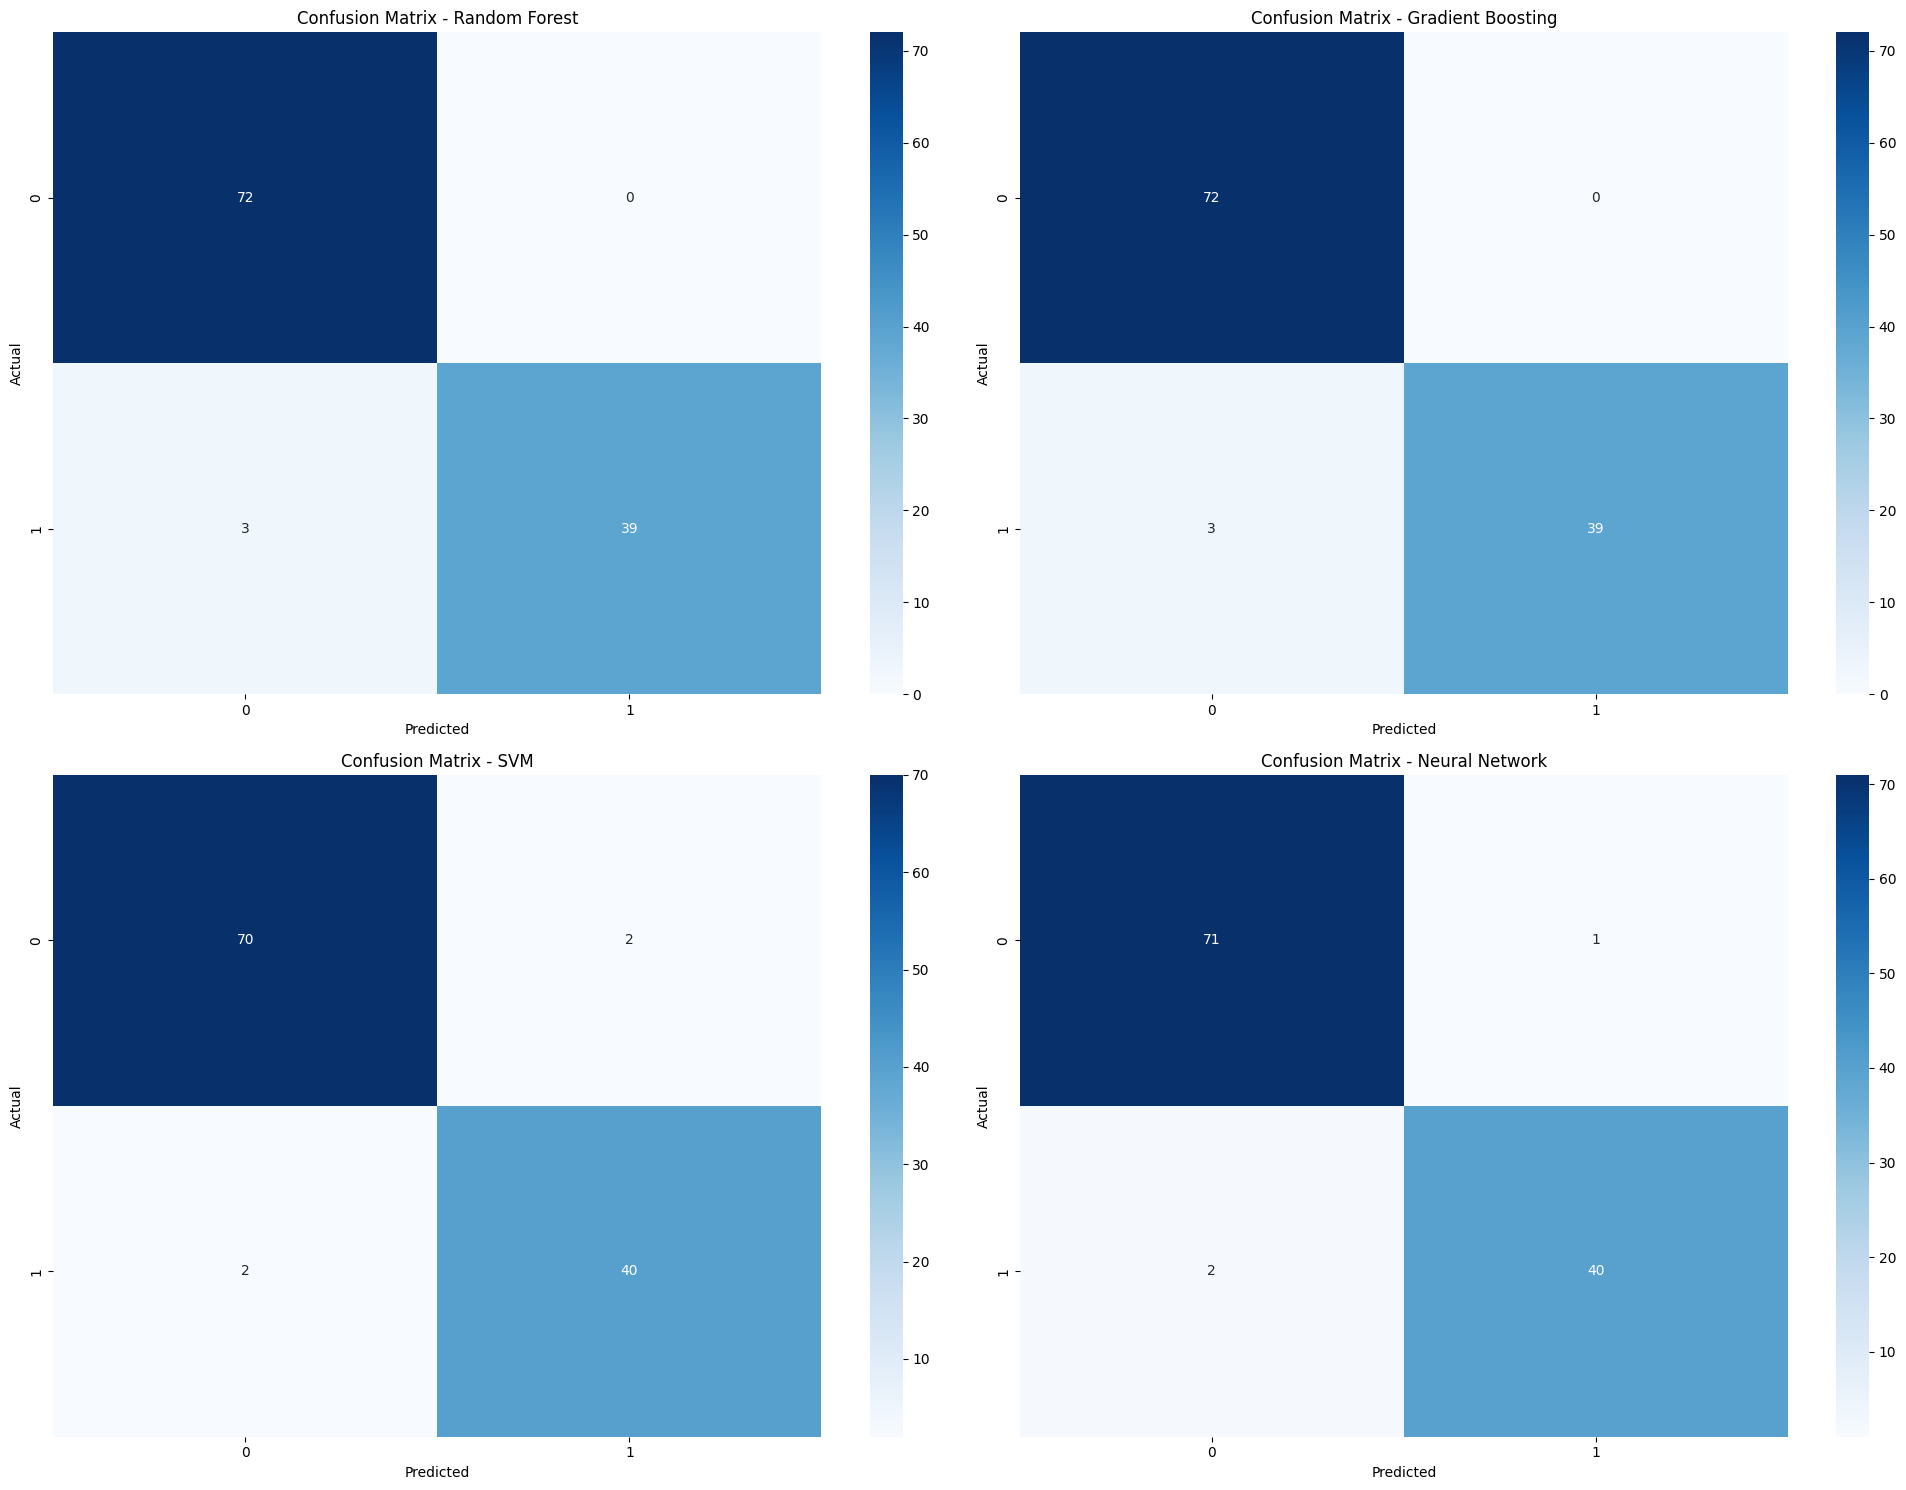

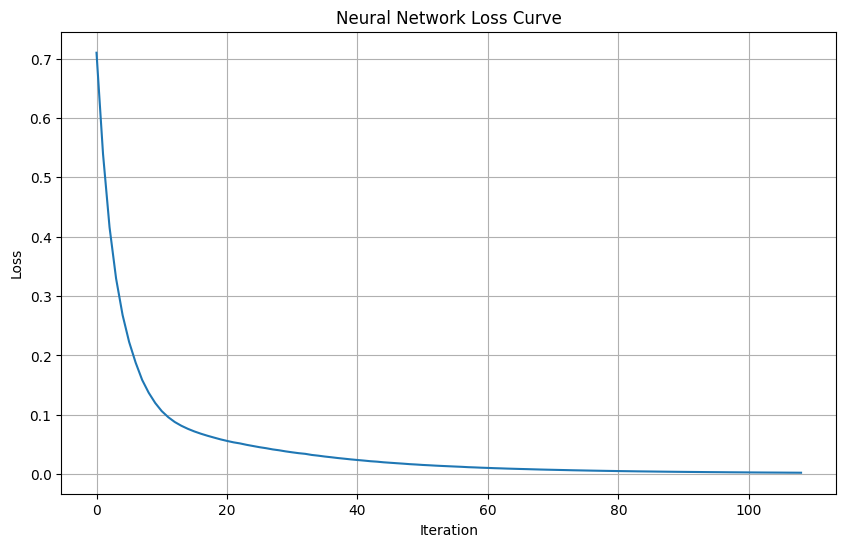

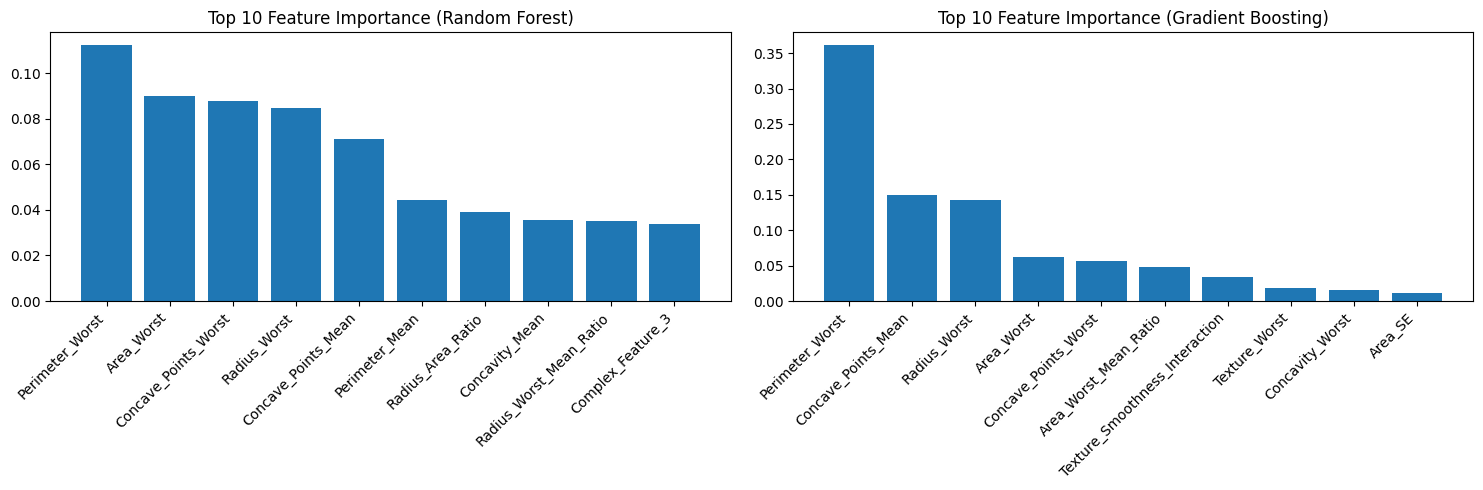

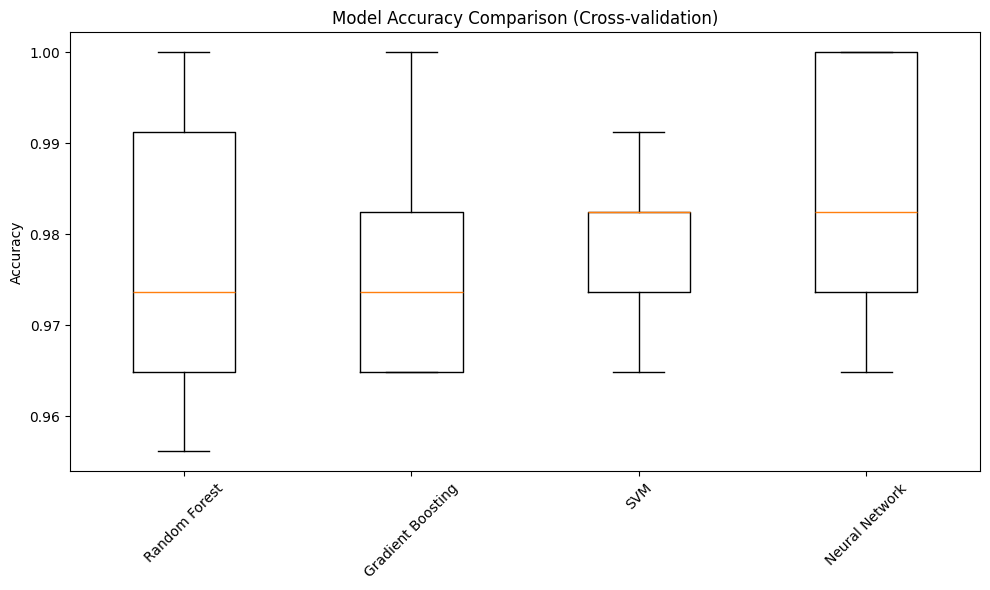


Ensemble Model Results:
Best Threshold: 0.420
Accuracy: 0.9912

Ensemble Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99        72
           1       1.00      0.98      0.99        42

    accuracy                           0.99       114
   macro avg       0.99      0.99      0.99       114
weighted avg       0.99      0.99      0.99       114



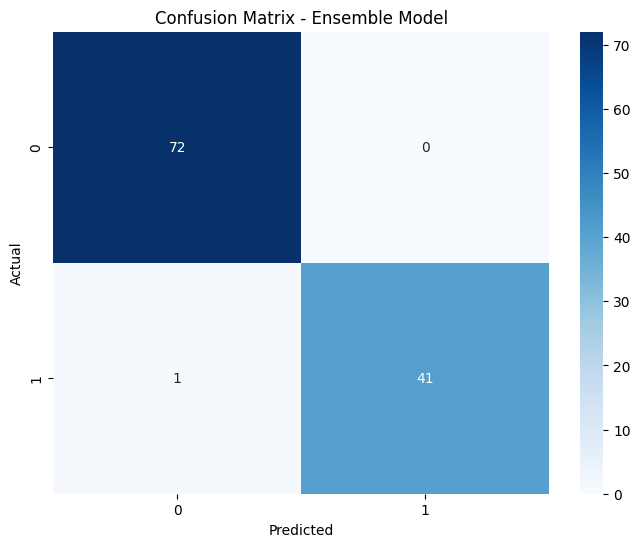

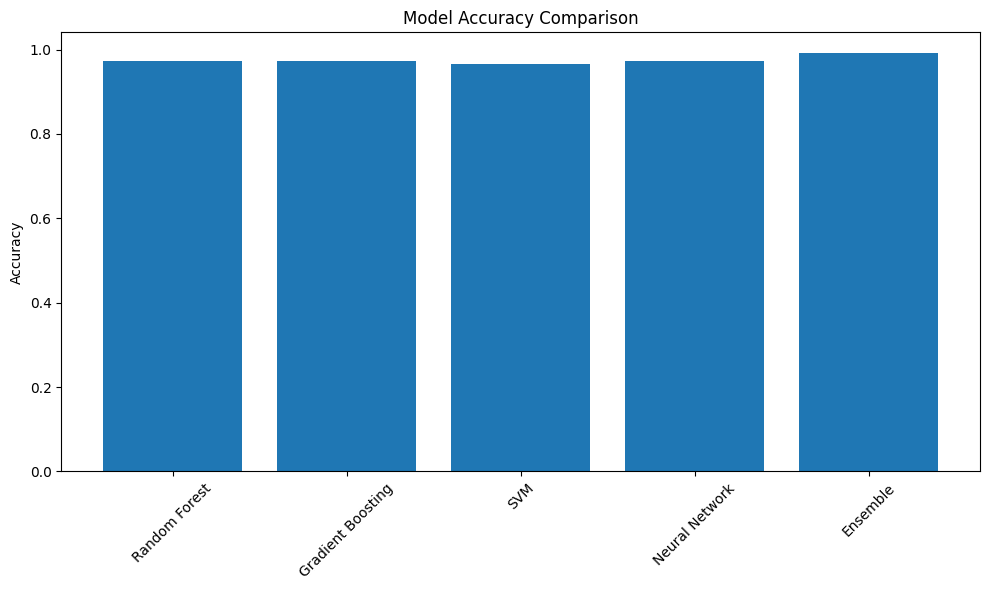

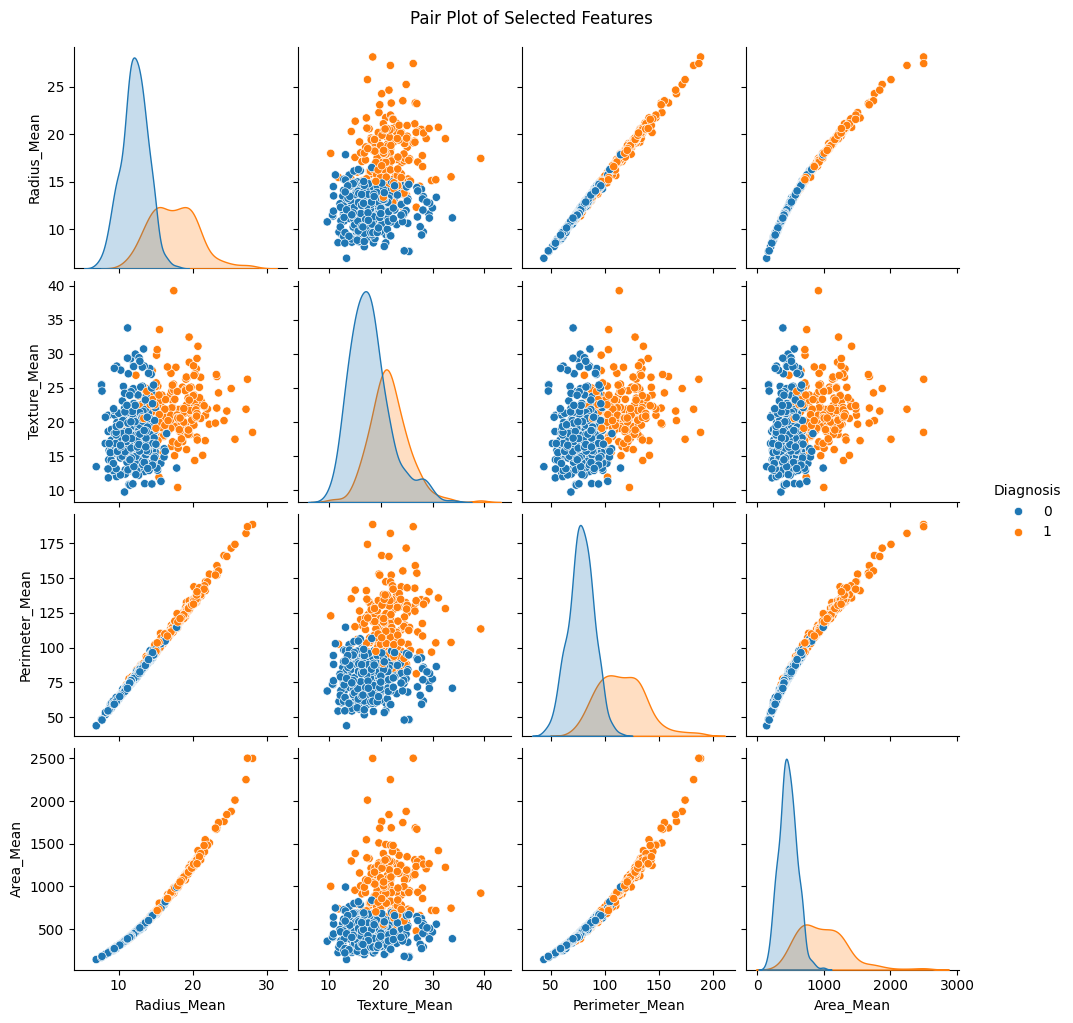

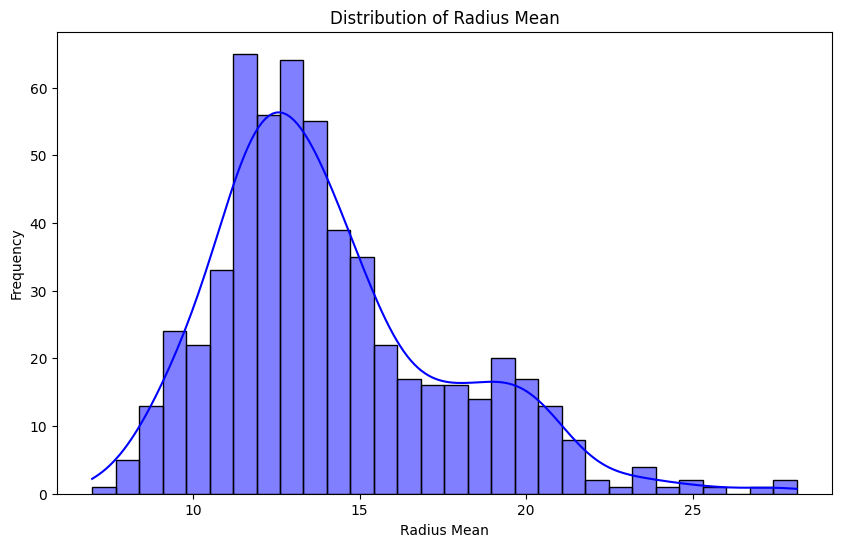

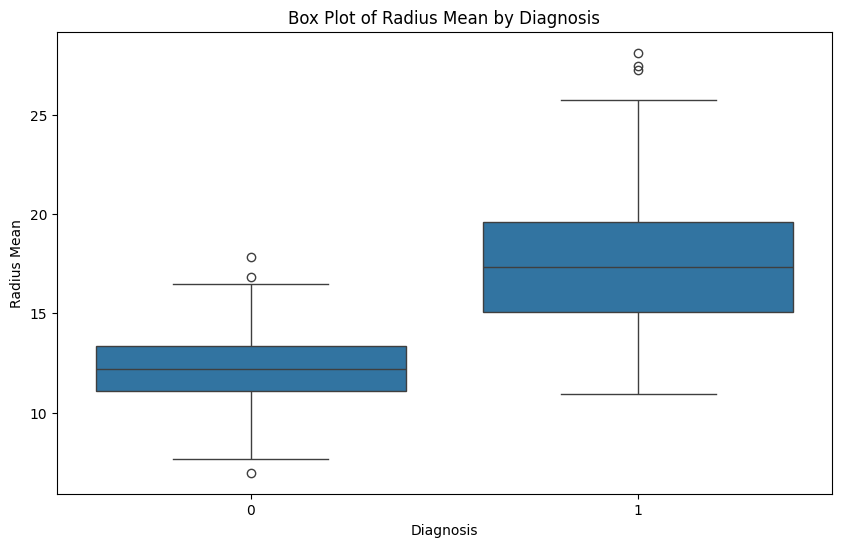

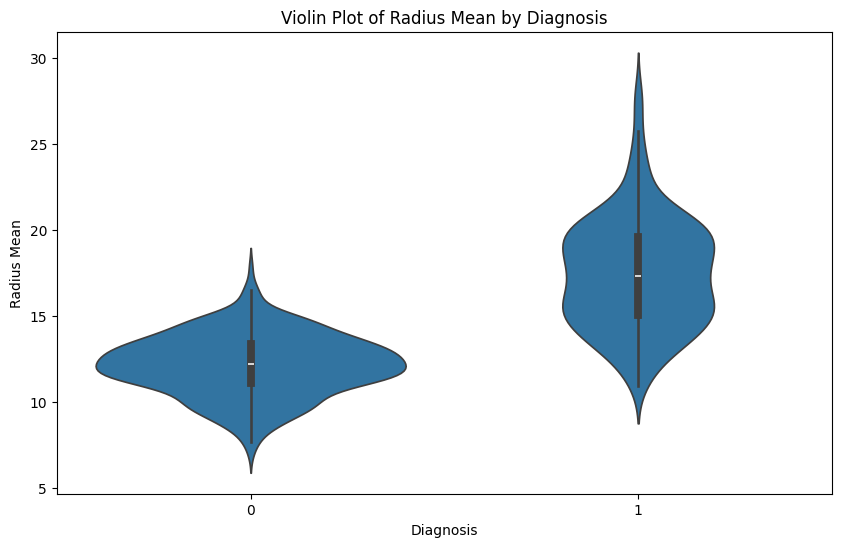

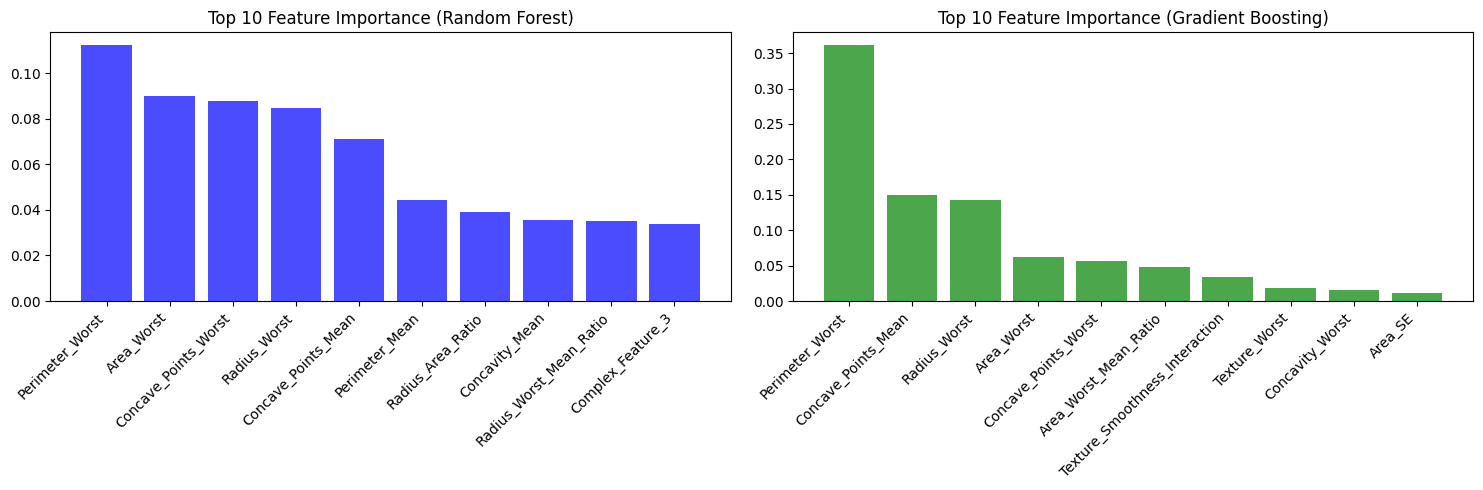

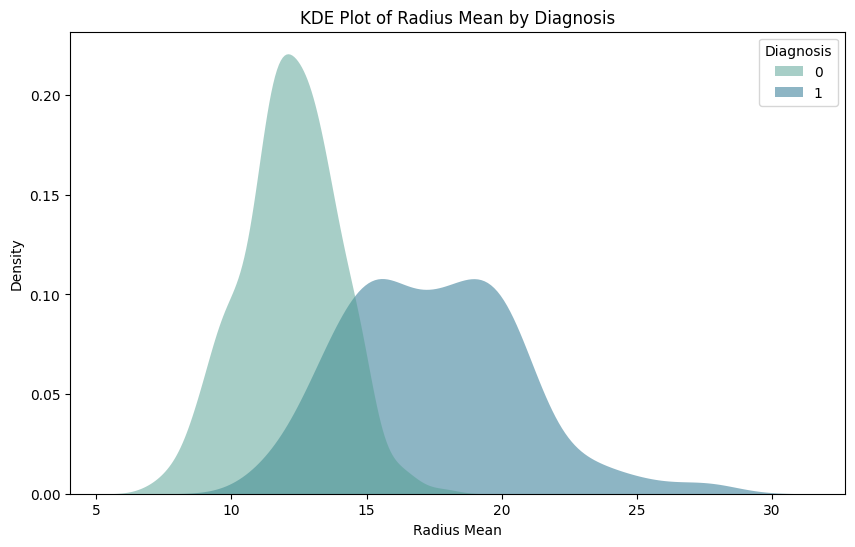

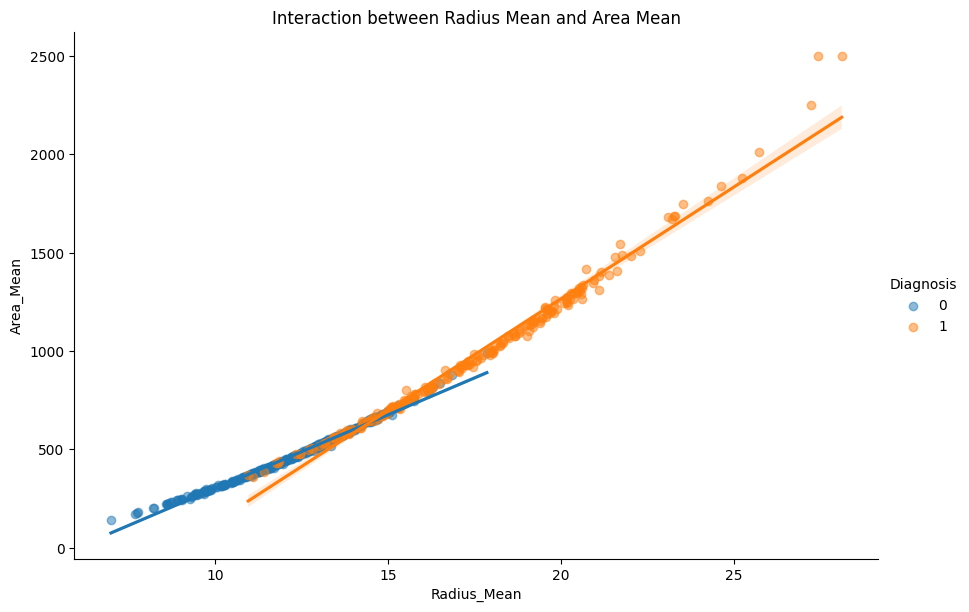

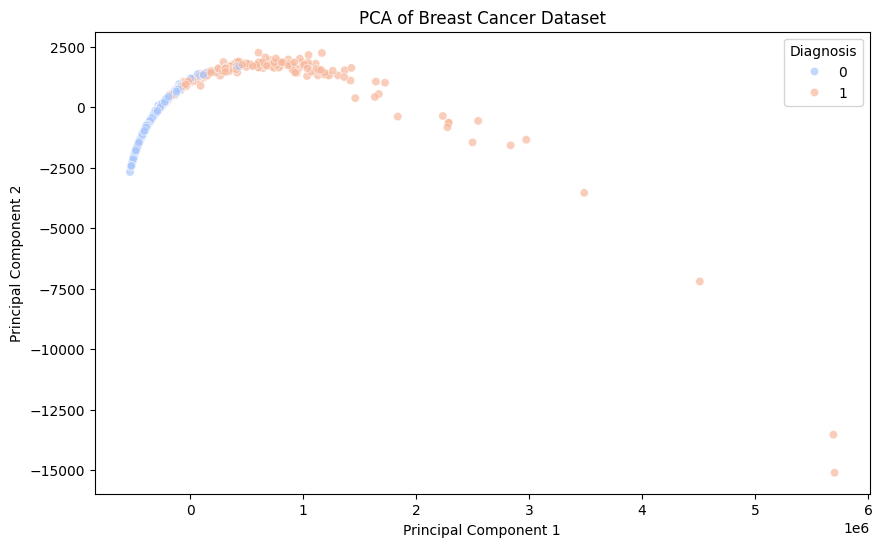

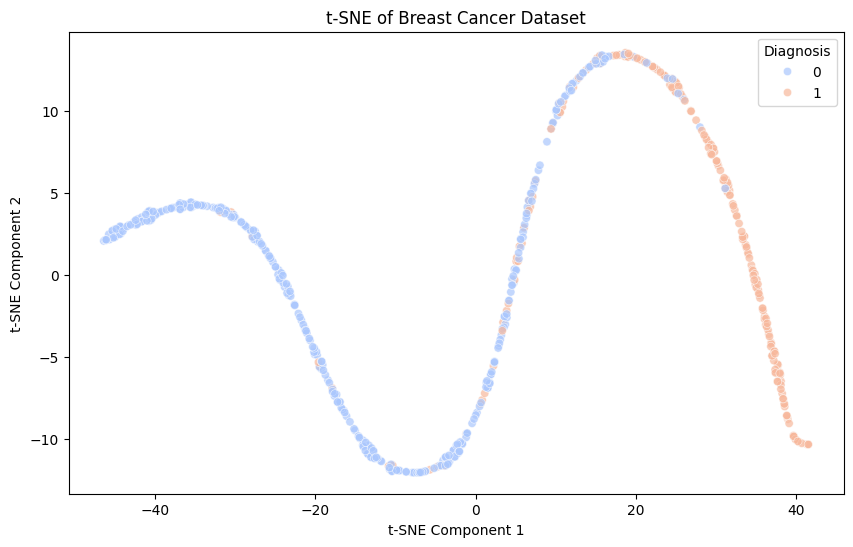

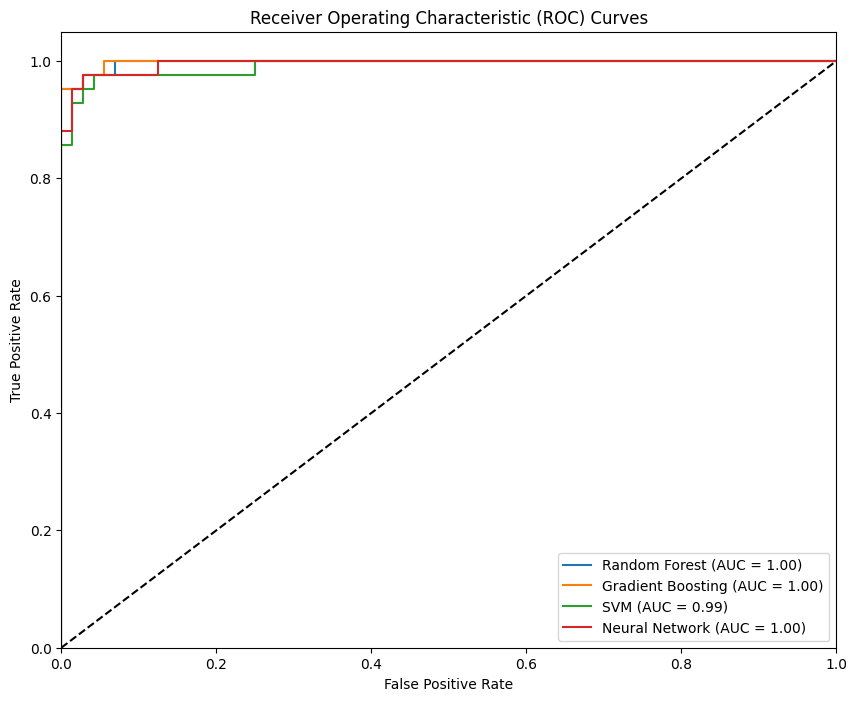

Selected Features: Index(['Radius_Mean', 'Perimeter_Mean', 'Area_Mean', 'Concave_Points_Mean',
       'Radius_Worst', 'Perimeter_Worst', 'Area_Worst', 'Concave_Points_Worst',
       'Radius_Mean_Squared', 'Complex_Feature_3'],
      dtype='object')


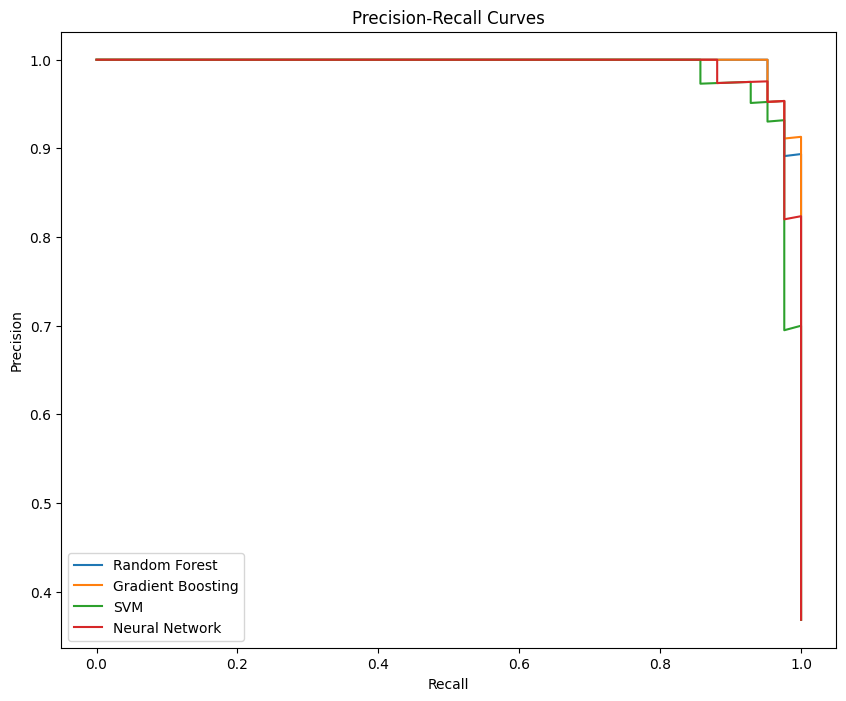

Best parameters found:  {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
Best cross-validation accuracy: 0.98


<Figure size 1600x1400 with 0 Axes>

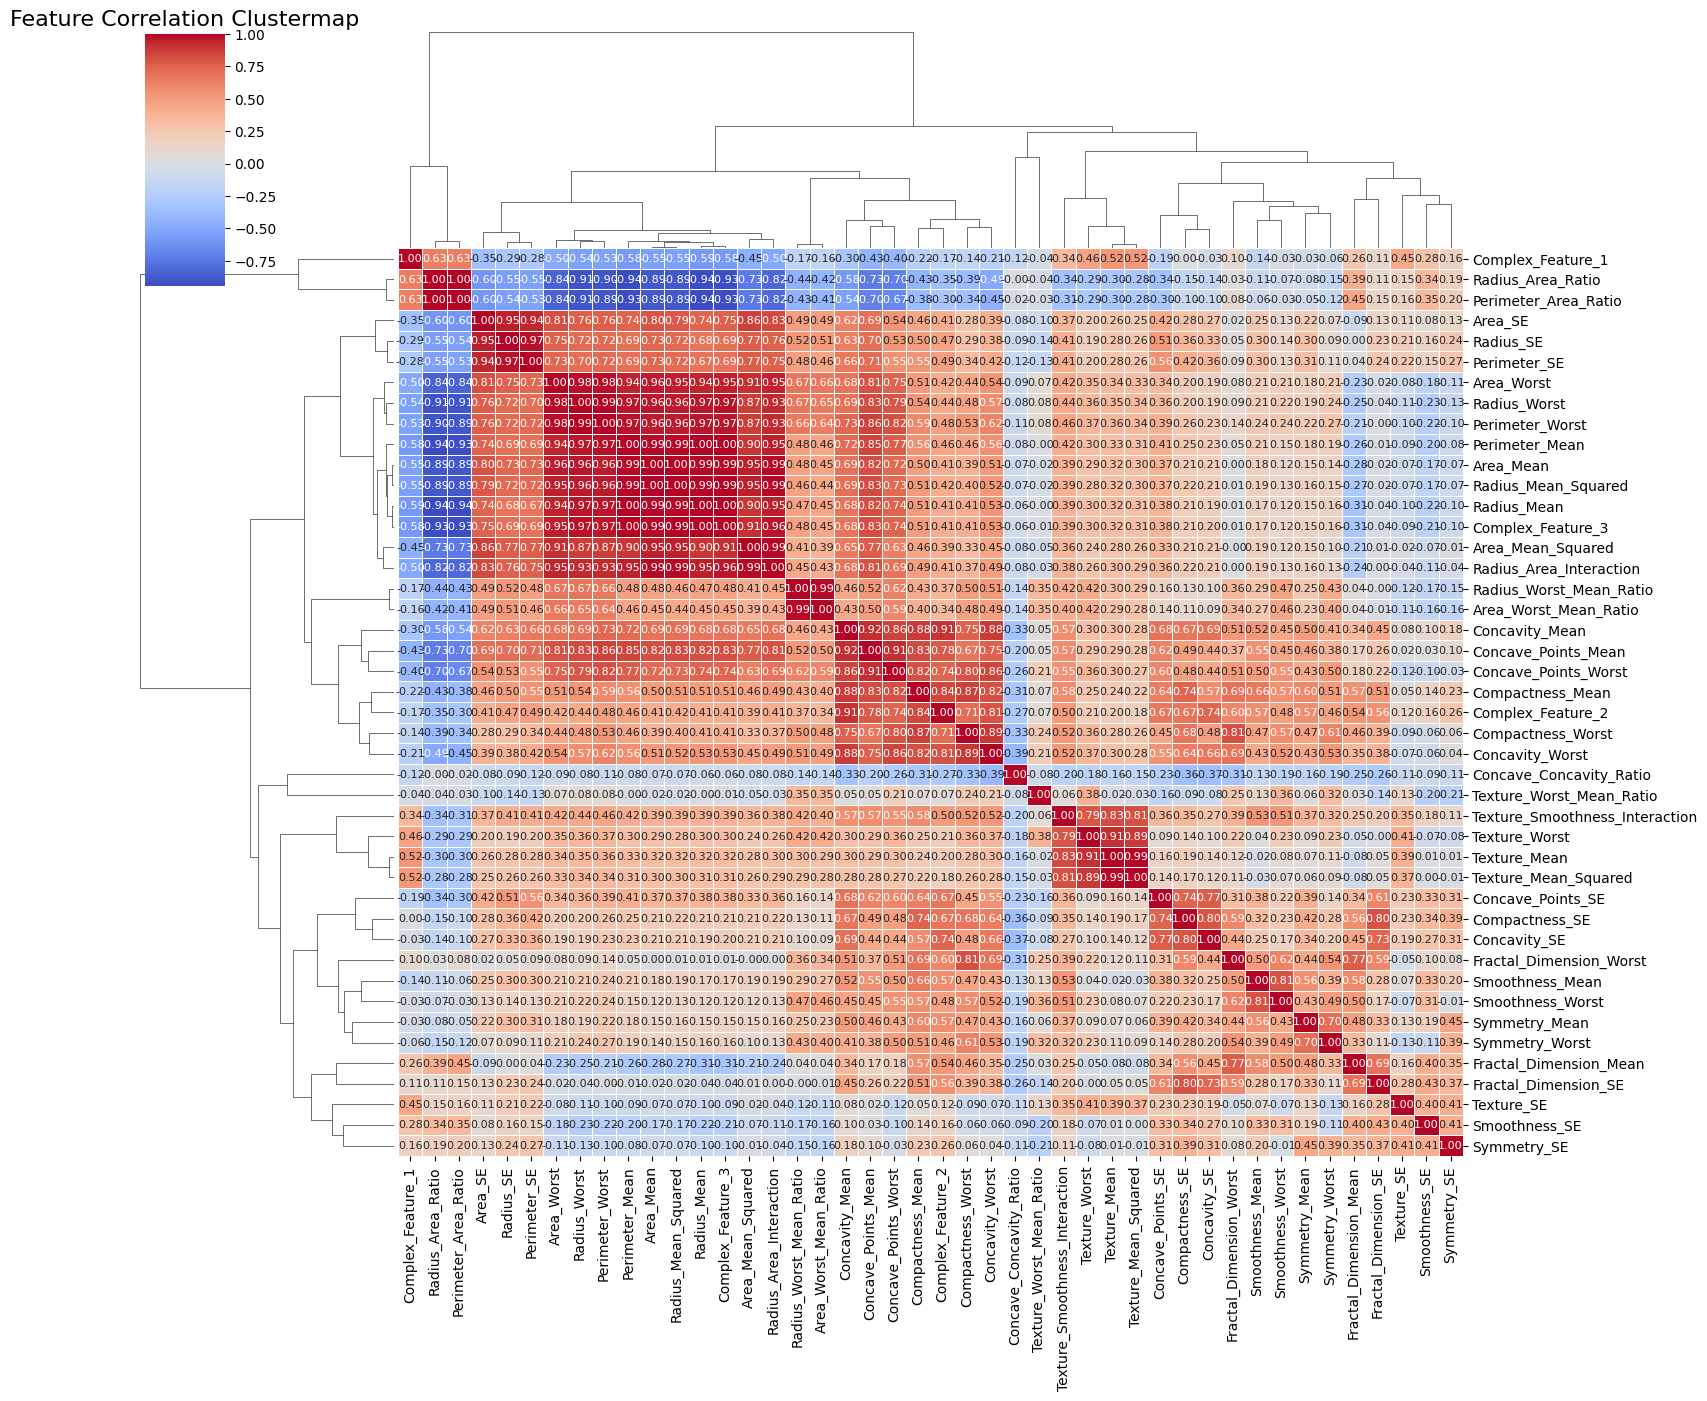

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from imblearn.over_sampling import SMOTE
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# Load dataset
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/wdbc.data"
column_names = [
    "ID", "Diagnosis", "Radius_Mean", "Texture_Mean", "Perimeter_Mean", "Area_Mean", "Smoothness_Mean",
    "Compactness_Mean", "Concavity_Mean", "Concave_Points_Mean", "Symmetry_Mean", "Fractal_Dimension_Mean",
    "Radius_SE", "Texture_SE", "Perimeter_SE", "Area_SE", "Smoothness_SE", "Compactness_SE", "Concavity_SE",
    "Concave_Points_SE", "Symmetry_SE", "Fractal_Dimension_SE", "Radius_Worst", "Texture_Worst", "Perimeter_Worst",
    "Area_Worst", "Smoothness_Worst", "Compactness_Worst", "Concavity_Worst", "Concave_Points_Worst",
    "Symmetry_Worst", "Fractal_Dimension_Worst"
]
data = pd.read_csv(url, header=None, names=column_names)

# Preprocessing
data = data.drop("ID", axis=1)
data['Diagnosis'] = data['Diagnosis'].map({'M': 1, 'B': 0})

# Feature engineering
X = data.drop("Diagnosis", axis=1)
y = data["Diagnosis"]

def create_polynomial_features(X):
    X = X.copy()

    # Basic ratios
    X['Radius_Area_Ratio'] = X['Radius_Mean'] / (X['Area_Mean'] + 1e-6)
    X['Perimeter_Area_Ratio'] = X['Perimeter_Mean'] / (X['Area_Mean'] + 1e-6)
    X['Concave_Concavity_Ratio'] = X['Concave_Points_Mean'] / (X['Concavity_Mean'] + 1e-6)

    # Advanced ratios
    X['Radius_Worst_Mean_Ratio'] = X['Radius_Worst'] / (X['Radius_Mean'] + 1e-6)
    X['Area_Worst_Mean_Ratio'] = X['Area_Worst'] / (X['Area_Mean'] + 1e-6)
    X['Texture_Worst_Mean_Ratio'] = X['Texture_Worst'] / (X['Texture_Mean'] + 1e-6)

    # Squared features
    for col in ['Radius_Mean', 'Area_Mean', 'Texture_Mean']:
        X[f'{col}_Squared'] = X[col] ** 2

    # Interaction features
    X['Radius_Area_Interaction'] = X['Radius_Mean'] * X['Area_Mean']
    X['Texture_Smoothness_Interaction'] = X['Texture_Mean'] * X['Smoothness_Mean']

    # Complex features
    X['Complex_Feature_1'] = (X['Radius_Mean'] * X['Texture_Mean']) / (X['Area_Mean'] + 1e-6)
    X['Complex_Feature_2'] = (X['Concavity_Mean'] * X['Concave_Points_Mean']) / (X['Area_Mean'] + 1e-6)
    X['Complex_Feature_3'] = np.log1p(X['Area_Mean']) * X['Radius_Mean']

    return X

X = create_polynomial_features(X)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Apply SMOTE
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train, y_train)

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_balanced)
X_test_scaled = scaler.transform(X_test)

# Create models
rf = RandomForestClassifier(n_estimators=1000, max_depth=None, min_samples_split=2,
                          min_samples_leaf=1, max_features='sqrt', bootstrap=True,
                          class_weight='balanced', random_state=42)

gb = GradientBoostingClassifier(n_estimators=1000, learning_rate=0.01, max_depth=5,
                               min_samples_split=2, min_samples_leaf=1, subsample=0.8,
                               random_state=42)

svm = SVC(C=10, kernel='rbf', probability=True, random_state=42)

nn = MLPClassifier(hidden_layer_sizes=(100, 50), activation='relu', solver='adam',
                  alpha=0.0001, learning_rate='adaptive', max_iter=1000, random_state=42)

# Dictionary of models
models = {
    'Random Forest': rf,
    'Gradient Boosting': gb,
    'SVM': svm,
    'Neural Network': nn
}

# Train models and store predictions
predictions = {}
for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train_scaled, y_train_balanced)
    predictions[name] = model.predict_proba(X_test_scaled)

# Plot confusion matrices for each model
plt.figure(figsize=(20, 15))
for i, (name, pred) in enumerate(predictions.items(), 1):
    model_pred = (pred[:, 1] >= 0.5).astype(int)

    # Print metrics
    print(f"\n{name} Results:")
    print(f"Accuracy: {accuracy_score(y_test, model_pred):.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, model_pred))

    # Plot confusion matrix
    cm = confusion_matrix(y_test, model_pred)
    plt.subplot(2, 2, i)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')

plt.tight_layout()
plt.show()

# Neural Network Learning Curve
plt.figure(figsize=(10, 6))
plt.plot(nn.loss_curve_)
plt.title('Neural Network Loss Curve')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.grid(True)
plt.show()

# Feature Importance Plots
plt.figure(figsize=(15, 5))

# Random Forest Feature Importance
plt.subplot(1, 2, 1)
importances_rf = rf.feature_importances_
indices_rf = np.argsort(importances_rf)[::-1][:10]
plt.title('Top 10 Feature Importance (Random Forest)')
plt.bar(range(10), importances_rf[indices_rf])
plt.xticks(range(10), X.columns[indices_rf], rotation=45, ha='right')

# Gradient Boosting Feature Importance
plt.subplot(1, 2, 2)
importances_gb = gb.feature_importances_
indices_gb = np.argsort(importances_gb)[::-1][:10]
plt.title('Top 10 Feature Importance (Gradient Boosting)')
plt.bar(range(10), importances_gb[indices_gb])
plt.xticks(range(10), X.columns[indices_gb], rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Cross-validation accuracy comparison
cv_scores_dict = {}
for name, model in models.items():
    cv_scores = cross_val_score(model, X_train_scaled, y_train_balanced, cv=5)
    cv_scores_dict[name] = cv_scores

plt.figure(figsize=(10, 6))
plt.boxplot(cv_scores_dict.values(), labels=cv_scores_dict.keys())
plt.title('Model Accuracy Comparison (Cross-validation)')
plt.ylabel('Accuracy')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Weighted Ensemble
weights = {
    'Random Forest': 0.35,
    'Gradient Boosting': 0.25,
    'SVM': 0.20,
    'Neural Network': 0.20
}

# Create ensemble predictions
ensemble_pred = np.zeros_like(predictions['Random Forest'])
for name, pred in predictions.items():
    ensemble_pred += pred * weights[name]

# Find optimal threshold
thresholds = np.arange(0.3, 0.7, 0.01)
best_accuracy = 0
best_threshold = 0.5

for threshold in thresholds:
    final_pred = (ensemble_pred[:, 1] >= threshold).astype(int)
    accuracy = accuracy_score(y_test, final_pred)
    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_threshold = threshold

# Final ensemble predictions
final_pred = (ensemble_pred[:, 1] >= best_threshold).astype(int)

# Print ensemble results
print("\nEnsemble Model Results:")
print(f"Best Threshold: {best_threshold:.3f}")
print(f"Accuracy: {accuracy_score(y_test, final_pred):.4f}")
print("\nEnsemble Classification Report:")
print(classification_report(y_test, final_pred))

# Plot ensemble confusion matrix
plt.figure(figsize=(8, 6))
cm_ensemble = confusion_matrix(y_test, final_pred)
sns.heatmap(cm_ensemble, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Ensemble Model')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Plot accuracy comparison including ensemble
accuracies = {}
for name, pred in predictions.items():
    model_pred = (pred[:, 1] >= 0.5).astype(int)
    accuracies[name] = accuracy_score(y_test, model_pred)
accuracies['Ensemble'] = accuracy_score(y_test, final_pred)

plt.figure(figsize=(10, 6))
plt.bar(accuracies.keys(), accuracies.values())
plt.title('Model Accuracy Comparison')
plt.ylabel('Accuracy')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# Correlation matrix
corr_matrix = X.corr()

# Pair plot
sns.pairplot(data, hue='Diagnosis', vars=['Radius_Mean', 'Texture_Mean', 'Perimeter_Mean', 'Area_Mean'])
plt.suptitle('Pair Plot of Selected Features', y=1.02)
plt.show()

# Distribution plot for a specific feature
plt.figure(figsize=(10, 6))
sns.histplot(data['Radius_Mean'], kde=True, bins=30, color='blue')
plt.title('Distribution of Radius Mean')
plt.xlabel('Radius Mean')
plt.ylabel('Frequency')
plt.show()


# Box plot for a specific feature
plt.figure(figsize=(10, 6))
sns.boxplot(x='Diagnosis', y='Radius_Mean', data=data)
plt.title('Box Plot of Radius Mean by Diagnosis')
plt.xlabel('Diagnosis')
plt.ylabel('Radius Mean')
plt.show()

# Violin plot for a specific feature
plt.figure(figsize=(10, 6))
sns.violinplot(x='Diagnosis', y='Radius_Mean', data=data)
plt.title('Violin Plot of Radius Mean by Diagnosis')
plt.xlabel('Diagnosis')
plt.ylabel('Radius Mean')
plt.show()


# Feature importance comparison
plt.figure(figsize=(15, 5))

# Random Forest Feature Importance
plt.subplot(1, 2, 1)
importances_rf = rf.feature_importances_
indices_rf = np.argsort(importances_rf)[::-1][:10]
plt.title('Top 10 Feature Importance (Random Forest)')
plt.bar(range(10), importances_rf[indices_rf], color='b', alpha=0.7)
plt.xticks(range(10), X.columns[indices_rf], rotation=45, ha='right')

# Gradient Boosting Feature Importance
plt.subplot(1, 2, 2)
importances_gb = gb.feature_importances_
indices_gb = np.argsort(importances_gb)[::-1][:10]
plt.title('Top 10 Feature Importance (Gradient Boosting)')
plt.bar(range(10), importances_gb[indices_gb], color='g', alpha=0.7)
plt.xticks(range(10), X.columns[indices_gb], rotation=45, ha='right')

plt.tight_layout()
plt.show()


# KDE plot for a specific feature
plt.figure(figsize=(10, 6))
sns.kdeplot(data=data, x='Radius_Mean', hue='Diagnosis', fill=True, common_norm=False, palette='crest', alpha=.5, linewidth=0)
plt.title('KDE Plot of Radius Mean by Diagnosis')
plt.xlabel('Radius Mean')
plt.ylabel('Density')
plt.show()

# Pairwise feature interaction plot
sns.lmplot(x='Radius_Mean', y='Area_Mean', hue='Diagnosis', data=data, aspect=1.5, height=6, scatter_kws={'alpha':0.5})
plt.title('Interaction between Radius Mean and Area Mean')
plt.show()
'''
# Log transformation of skewed features
X['Log_Radius_Mean'] = np.log1p(X['Radius_Mean'])
X['Log_Area_Mean'] = np.log1p(X['Area_Mean'])
# Polynomial features
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(X[['Radius_Mean', 'Texture_Mean', 'Perimeter_Mean']])
X_poly_df = pd.DataFrame(X_poly, columns=poly.get_feature_names_out(['Radius_Mean', 'Texture_Mean', 'Perimeter_Mean']))
X = pd.concat([X, X_poly_df], axis=1)
# Interaction terms
X['Radius_Texture_Interaction'] = X['Radius_Mean'] * X['Texture_Mean']
X['Perimeter_Area_Interaction'] = X['Perimeter_Mean'] * X['Area_Mean']'''
from sklearn.decomposition import PCA

# Apply PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# Plot PCA
plt.figure(figsize=(10, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y, palette='coolwarm', alpha=0.7)
plt.title('PCA of Breast Cancer Dataset')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.show()
from sklearn.manifold import TSNE

# Apply t-SNE
tsne = TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(X)

# Plot t-SNE
plt.figure(figsize=(10, 6))
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=y, palette='coolwarm', alpha=0.7)
plt.title('t-SNE of Breast Cancer Dataset')
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.show()

from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(10, 8))
for name, model in models.items():
    y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curves')
plt.legend(loc='lower right')
plt.show()

from sklearn.feature_selection import SelectKBest, f_classif

# Select top 10 features based on ANOVA F-test
selector = SelectKBest(score_func=f_classif, k=10)
X_selected = selector.fit_transform(X, y)
selected_features = X.columns[selector.get_support()]

print("Selected Features:", selected_features)

from sklearn.metrics import precision_recall_curve

plt.figure(figsize=(10, 8))
for name, model in models.items():
    y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]
    precision, recall, _ = precision_recall_curve(y_test, y_pred_proba)
    plt.plot(recall, precision, label=name)

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curves')
plt.legend(loc='lower left')
plt.show()

from sklearn.model_selection import GridSearchCV

# Example for Random Forest
param_grid = {
    'n_estimators': [100, 500, 1000],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

grid_search = GridSearchCV(rf, param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train_scaled, y_train_balanced)

print("Best parameters found: ", grid_search.best_params_)
print("Best cross-validation accuracy: {:.2f}".format(grid_search.best_score_))

# Improved Clustermap
plt.figure(figsize=(16, 14))  # Increase figure size for better readability
sns.clustermap(
    corr_matrix,
    cmap='coolwarm',
    annot=True,
    fmt=".2f",
    linewidths=.5,
    annot_kws={"size": 8},  # Adjust font size for annotations
    figsize=(16, 14)  # Set the size of the clustermap
)
plt.title('Feature Correlation Clustermap', fontsize=16)
plt.show()